# 04. Feature Engineering and Feature Selection

**Input:** `data/processed/oulad_master_day28.csv` and the raw tables.
**Output:** `data/processed/oulad_features_day28.csv` (engineered features, split label) and the selected feature list.

Decisions carried in from notebook 03:

1. Rebuild early-score features from raw submissions, because one BBB 2014J assessment is coded only 100 or 1.
2. Build engagement features relative to each module-presentation (modules differ about 10x in activity).
3. `log1p` for click counts, cap `studied_credits` at 360 and previous attempts at 3, drop near-constant flags.
4. Add a `has_early_score` indicator instead of imputing scores.

**Leakage rules for this notebook**

- Every feature uses only information dated before day 28.
- Module-relative features use only other students' day-28 *features* (never labels), so they can be computed for a new presentation at day 28.
- **Feature selection uses the training years (2013) only.** The 2014 rows are not touched until notebook 07.
- Fitted steps (imputation, scaling, encoding) live inside cross-validated pipelines.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
CUTOFF_DAY = 28
RAW, PROC, OUT = Path("../data/raw"), Path("../data/processed"), Path("../outputs")
FIG = OUT / "figures"
KEY = ["code_module", "code_presentation", "id_student"]
MP = ["code_module", "code_presentation"]
NA = ["?"]
MIN_ASSESS_N = 30  # an assessment needs at least this many early submissions for a percentile rank to mean anything
assert CUTOFF_DAY == 28, "weekly features below assume four weeks"

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_OK, C_RISK = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
def savefig(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

def auc_pos(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    a, b = d.loc[d.y == 1, "x"], d.loc[d.y == 0, "x"]
    return float(stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)))

master = pd.read_csv(PROC / "oulad_master_day28.csv")
print("master:", master.shape)

master: (27553, 46)


## 1. Rebuild the early assessment features

### 1.1 Find binary-coded assessments

An assessment is flagged as binary-coded when two score values cover at least 95% of submissions **and the second value is at least 30% of them**, i.e. the two codes are balanced.
This keeps out ordinary quizzes where most students score 100 and a minority score 80 (the closest such cases are listed below the flagged one so the threshold can be checked).

In [2]:
sa = pd.read_csv(RAW / "studentAssessment.csv", na_values=NA)
asm = pd.read_csv(RAW / "assessments.csv", na_values=NA).rename(columns={"date": "due_date"})
sc = sa.merge(asm, on="id_assessment", how="left", validate="many_to_one")
assert sc.code_module.notna().all()

def profile(g):
    vc = g.score.dropna().round(0).value_counts(normalize=True)
    return pd.Series(dict(n=int(g.score.notna().sum()), distinct=len(vc), top1_share=vc.iloc[0],
                          top2_share=vc.iloc[1] if len(vc) > 1 else 0.0, top2_cum=vc.iloc[:2].sum(),
                          value1=vc.index[0], value2=vc.index[1] if len(vc) > 1 else np.nan))
prof = (sc.groupby(["code_module", "code_presentation", "id_assessment", "assessment_type"])
          .apply(profile, include_groups=False).reset_index())
flag = prof[(prof.top2_cum >= 0.95) & (prof.top2_share >= 0.30) & (prof.n >= 50)]
BINARY_IDS = set(flag.id_assessment)
print(f"{len(prof)} assessments profiled; {len(flag)} flagged as binary-coded:")
display(flag)
print("closest non-flagged assessments (top-two values cover most submissions):")
display(prof[~prof.id_assessment.isin(BINARY_IDS) & (prof.n >= 50)].sort_values("top2_cum", ascending=False).head(4))

188 assessments profiled; 1 flagged as binary-coded:


,code_module,code_presentation,id_assessment,assessment_type,n,distinct,top1_share,top2_share,top2_cum,value1,value2
43,BBB,2014J,15020,TMA,"1,772.000",9.000,0.577,0.405,0.981,100.000,1.000


closest non-flagged assessments (top-two values cover most submissions):


,code_module,code_presentation,id_assessment,assessment_type,n,distinct,top1_share,top2_share,top2_cum,value1,value2
27,BBB,2013J,15003,CMA,"1,490.000",5.000,0.739,0.211,0.950,100.000,80.000
38,BBB,2014B,15015,CMA,"1,054.000",5.000,0.753,0.196,0.950,100.000,80.000
16,BBB,2013B,14991,CMA,"1,189.000",6.000,0.760,0.188,0.949,100.000,80.000
185,GGG,2014J,37441,CMA,473.000,6.000,0.700,0.224,0.924,100.000,80.000


### 1.2 Percentile-rank scores, timeliness and binary completion

In [3]:
early = sc[(sc.date_submitted < CUTOFF_DAY) & (sc.is_banked == 0)].copy()
assert early.date_submitted.max() < CUTOFF_DAY
early["is_binary"] = early.id_assessment.isin(BINARY_IDS)

# Percentile rank of each score among the early submissions of the SAME assessment (needs no labels, computable at day 28)
ordinary = early[~early.is_binary].copy()
n_early = ordinary.groupby("id_assessment").size()
print("early submissions per ordinary assessment:", n_early.describe()[["min", "50%", "max"]].to_dict(),
      "| assessments below the minimum of", MIN_ASSESS_N, ":", int((n_early < MIN_ASSESS_N).sum()))
ordinary["pct"] = ordinary.groupby("id_assessment").score.rank(pct=True, method="average")
ordinary.loc[ordinary.id_assessment.map(n_early) < MIN_ASSESS_N, "pct"] = np.nan

f_score = ordinary.groupby(KEY).agg(score_pct_mean=("pct", "mean"), score_pct_min=("pct", "min"))

# Timeliness: days before the due date (negative = after). Due dates are known in advance; exams have no due date.
early["days_before_due"] = early.due_date - early.date_submitted
early["after_due"] = (early.date_submitted > early.due_date).astype(int)
f_time = early.groupby(KEY).agg(days_before_due_mean=("days_before_due", "mean"), n_submitted_after_due=("after_due", "sum"))

# Binary-coded assessments: keep only as a completion indicator (1 = the higher of the two codes)
bi = early[early.is_binary].copy()
bi["binary_high"] = (bi.score == bi.groupby("id_assessment").score.transform("max")).astype(int)
f_bin = bi.groupby(KEY).agg(n_binary_submitted=("id_assessment", "size"), binary_high=("binary_high", "mean"))

F = master.merge(f_score, on=KEY, how="left", validate="one_to_one") \
          .merge(f_time, on=KEY, how="left", validate="one_to_one") \
          .merge(f_bin, on=KEY, how="left", validate="one_to_one")
F["n_binary_submitted"] = F.n_binary_submitted.fillna(0).astype(int)
F["n_submitted_after_due"] = F.n_submitted_after_due.fillna(0).astype(int)
F["has_early_score"] = F.score_pct_mean.notna().astype(int)

# Reconciliation: ordinary + binary submissions must equal the n_assess_submitted from notebook 02
n_ord = ordinary.groupby(KEY).size().rename("n_ord").reset_index()
chk = F[KEY + ["n_assess_submitted", "n_binary_submitted"]].merge(n_ord, on=KEY, how="left").fillna({"n_ord": 0})
assert (chk.n_ord + chk.n_binary_submitted == chk.n_assess_submitted).all(), "submission counts do not reconcile"
print("submission counts reconcile with notebook 02 for all", len(F), "students")

early submissions per ordinary assessment: {'min': 1.0, '50%': 165.5, 'max': 1878.0} | assessments below the minimum of 30 : 14
submission counts reconcile with notebook 02 for all 27553 students


students with an old early mean of about 1: 671 | now with a binary-coded submission: 1674
of those old 'about 1' students, share that now have NO ordinary score: 1.0

Students with a binary-coded early submission, by presentation year:


,students,share
year,,
2013,0,0.000
2014,1674,0.106



At-risk rate by binary completion code (1 = higher code):


,n,at_risk_rate
binary_high,,
0.000,706,0.348
1.000,968,0.298
NaN,25879,0.450


,AUC (higher value = less at risk)
old mean_score_early,0.674
new score_pct_mean,0.695
new score_pct_min,0.684


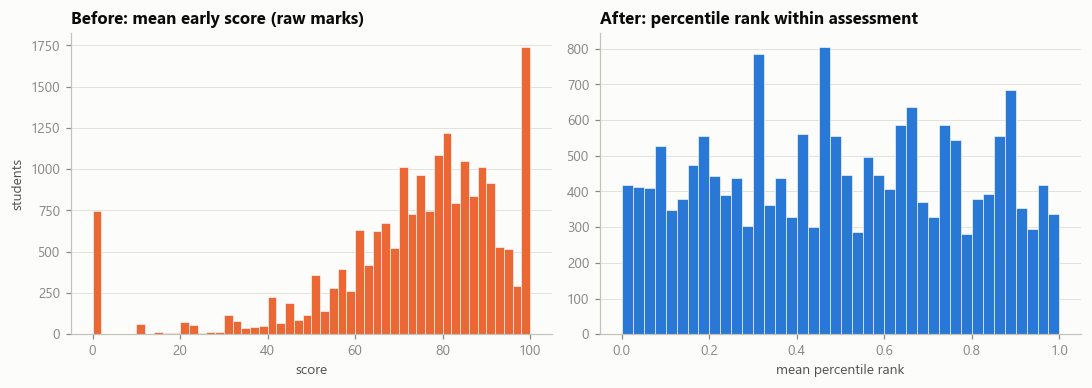

In [4]:
# Did the rebuild remove the artefact?
old = F.mean_score_early
print("students with an old early mean of about 1:", int(old.between(0.5, 1.5).sum()),
      "| now with a binary-coded submission:", int((F.n_binary_submitted > 0).sum()))
print("of those old 'about 1' students, share that now have NO ordinary score:", round(F.loc[old.between(0.5, 1.5), "score_pct_mean"].isna().mean(), 3))
print("\nStudents with a binary-coded early submission, by presentation year:")
display(F.assign(has_binary=F.n_binary_submitted > 0).groupby("year").has_binary.agg(students="sum", share="mean"))
print("\nAt-risk rate by binary completion code (1 = higher code):")
display(F.groupby("binary_high", dropna=False).target_at_risk.agg(n="size", at_risk_rate="mean"))

cmp_ = pd.DataFrame({"old mean_score_early": [1 - auc_pos(old, F.target_at_risk)], "new score_pct_mean": [1 - auc_pos(F.score_pct_mean, F.target_at_risk)],
                     "new score_pct_min": [1 - auc_pos(F.score_pct_min, F.target_at_risk)]}, index=["AUC (higher value = less at risk)"]).T
display(cmp_)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(old.dropna(), bins=50, color=C_RISK, edgecolor=SURFACE, linewidth=0.4); axes[0].set_title("Before: mean early score (raw marks)")
axes[0].set_xlabel("score"); axes[0].set_ylabel("students"); axes[0].grid(axis="x", visible=False)
axes[1].hist(F.score_pct_mean.dropna(), bins=40, color=C_OK, edgecolor=SURFACE, linewidth=0.4); axes[1].set_title("After: percentile rank within assessment")
axes[1].set_xlabel("mean percentile rank"); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); savefig(fig, "04_score_rebuild.png"); plt.show()

**Observed.** Two assessments were examined and only one is binary-coded: BBB 2014J assessment 15020 (scores 100 or 1, with the two codes at 58% and 41%). The closest non-flagged cases are ordinary 100 and 80 quizzes (second value about 19 to 24%), so the threshold separates them cleanly.
All 671 students whose old early mean was exactly 1 now have no ordinary score and a binary-coded submission. In total 1,674 students (10.6% of the 2014 rows, **none of the 2013 rows**) have a binary-coded early submission.
The new rank-based score separates at-risk students slightly better than the old mean (AUC 0.695 vs 0.674).

**Why it matters.** The artefact exists only in a 2014 presentation. A model trained on 2013 with the old score feature would meet raw scores of 1 for the first time in the test set, a built-in drift trap that would have appeared as a mysterious drop in test performance.
**Action.** Use `score_pct_mean` (percentile rank within the same assessment) and `days_before_due_mean` instead of the raw mean. The two binary-completion features have no variation in the training years, so they are excluded from modelling and kept in the saved table for transparency.

## 2. Engagement features

### 2.1 Transforms, shares, trend and regularity

In [5]:
for w in ["prestart", "w1", "w2", "w3", "w4"]:
    F[f"log_clicks_{w}"] = np.log1p(F[f"clicks_{w}"])
F["log_clicks_total"] = np.log1p(F.clicks_total)
F["log_n_sites"] = np.log1p(F.n_sites)
F["log_clicks_per_active_day"] = np.log1p(np.where(F.active_days > 0, F.clicks_total / F.active_days.where(F.active_days > 0), 0))
F["prestart_share"] = np.where(F.clicks_total > 0, F.clicks_prestart / F.clicks_total.where(F.clicks_total > 0), 0)

# Weekly trend: least-squares slope of log weekly clicks over weeks 1 to 4
x = np.array([1, 2, 3, 4], dtype=float); xc = x - x.mean()
Y = F[[f"log_clicks_w{i}" for i in range(1, 5)]].to_numpy()
F["trend_slope"] = (Y @ xc) / (xc ** 2).sum()

# Activity-type shares (0 when the student has no clicks)
for t in ["forumng", "oucontent", "homepage", "quiz", "subpage", "resource"]:
    F[f"share_{t}"] = np.where(F.clicks_total > 0, F[f"clicks_{t}"] / F.clicks_total.where(F.clicks_total > 0), 0)

# Regularity from the daily log: active days after the start and the longest inactive stretch (days 0 to 27)
sv = pd.read_csv(RAW / "studentVle.csv", usecols=KEY[:2] + ["id_student", "date"],
                 dtype={"code_module": "category", "code_presentation": "category", "id_student": "int32", "date": "int16"})
sv = sv[sv["date"] >= 0]; sv = sv[sv["date"] < CUTOFF_DAY].astype({"code_module": "object", "code_presentation": "object"})
assert sv["date"].max() < CUTOFF_DAY
d = sv.drop_duplicates().sort_values(KEY + ["date"])
d["prev"] = d.groupby(KEY)["date"].shift(1).fillna(-1)
d["gap"] = d["date"] - d["prev"] - 1
reg_feat = d.groupby(KEY).agg(active_days_poststart=("date", "size"), gap_inner=("gap", "max"), last_day=("date", "max"))
reg_feat["max_gap_poststart"] = np.maximum(reg_feat.gap_inner, (CUTOFF_DAY - 1) - reg_feat.last_day)
F = F.merge(reg_feat[["active_days_poststart", "max_gap_poststart"]].reset_index(), on=KEY, how="left", validate="one_to_one")
F["active_days_poststart"] = F.active_days_poststart.fillna(0).astype(int)
F["max_gap_poststart"] = F.max_gap_poststart.fillna(CUTOFF_DAY).astype(int)
assert (F.active_days_poststart <= F.active_days).all() and F.max_gap_poststart.between(0, CUTOFF_DAY).all()
print("regularity features built; no student has more post-start active days than active days overall")
F[["log_clicks_total", "trend_slope", "share_forumng", "active_days_poststart", "max_gap_poststart"]].describe().T

regularity features built; no student has more post-start active days than active days overall


,count,mean,std,min,25%,50%,75%,max
log_clicks_total,"27,553.000",5.103,1.576,0.000,4.489,5.403,6.138,8.932
trend_slope,"27,553.000",-0.040,0.594,-2.431,-0.363,-0.020,0.264,2.455
share_forumng,"27,553.000",0.206,0.196,0.000,0.036,0.164,0.316,1.000
active_days_poststart,"27,553.000",10.653,7.193,0.000,5.000,10.000,16.000,28.000
max_gap_poststart,"27,553.000",8.512,6.813,0.000,4.000,6.000,11.000,28.000


### 2.2 Engagement relative to the module-presentation

Each student's rank among the students of the *same module-presentation*, using day-28 behaviour only.

In [6]:
grp = F.groupby(MP)
print("smallest module-presentation group:", int(grp.size().min()), "students")
F["eng_pct_clicks"] = grp.clicks_total.rank(pct=True)
F["eng_pct_active_days"] = grp.active_days.rank(pct=True)
F["eng_pct_sites"] = grp.n_sites.rank(pct=True)
F["eng_pct_poststart_days"] = grp.active_days_poststart.rank(pct=True)
F["eng_z_logclicks"] = grp.log_clicks_total.transform(lambda s: (s - s.mean()) / s.std(ddof=0))

rows = []
for c in ["clicks_total", "eng_pct_clicks", "eng_z_logclicks", "active_days", "eng_pct_active_days"]:
    within = [1 - auc_pos(g[c], g.target_at_risk) for _, g in F.groupby("code_module")]
    rows.append(dict(feature=c, pooled_auc=1 - auc_pos(F[c], F.target_at_risk), mean_within_module_auc=np.mean(within), min_within=np.min(within), max_within=np.max(within)))
display(pd.DataFrame(rows).set_index("feature"))

smallest module-presentation group: 348 students


,pooled_auc,mean_within_module_auc,min_within,max_within
feature,,,,
clicks_total,0.661,0.689,0.640,0.742
eng_pct_clicks,0.694,0.689,0.643,0.740
eng_z_logclicks,0.694,0.689,0.642,0.740
active_days,0.665,0.692,0.644,0.751
eng_pct_active_days,0.695,0.693,0.648,0.751


**Observed.** Ranking each student inside their own module-presentation raises the pooled AUC from 0.661 (raw clicks) to 0.694, and from 0.665 to 0.695 for active days.
The mean AUC *within* modules is essentially unchanged (0.689 for clicks, 0.692 vs 0.693 for active days), because a rank within a module is a monotone transformation of the raw value there.
**Why it matters.** The relative features remove the module-level differences in activity that blurred the pooled comparison (notebook 03), without losing the within-module signal.
**Action.** Keep them as candidates. Whether they help a model that already knows the module is tested in the ablation below.

## 3. Cleaning transforms and the final feature table

In [7]:
F["credits_capped"] = F.studied_credits.clip(upper=360)
F["num_prev_capped"] = F.num_of_prev_attempts.clip(upper=3)
F["male"] = (F.gender == "M").astype(int)
F["disab"] = (F.disability == "Y").astype(int)
F["start_B"] = (F.start_term == "B").astype(int)
F["has_assessment_due"] = (F.n_assess_due > 0).astype(int)

GROUPS = {
    "context": {"num": ["start_B", "module_presentation_length", "has_assessment_due"], "cat": ["code_module"]},
    "background": {"num": ["edu_level", "imd_order", "imd_missing", "age_order", "disab", "male", "num_prev_capped", "credits_capped", "date_registration"], "cat": ["region"]},
    "engagement_raw": {"num": ["log_clicks_total", "log_clicks_prestart", "log_clicks_w1", "log_clicks_w2", "log_clicks_w3", "log_clicks_w4", "log_n_sites",
                               "active_days", "active_days_poststart", "max_gap_poststart", "first_click_day", "no_vle_activity", "log_clicks_per_active_day",
                               "prestart_share", "trend_slope", "share_forumng", "share_oucontent", "share_homepage", "share_quiz", "share_subpage", "share_resource"], "cat": []},
    "engagement_relative": {"num": ["eng_pct_clicks", "eng_pct_active_days", "eng_pct_sites", "eng_pct_poststart_days", "eng_z_logclicks"], "cat": []},
    "assessment": {"num": ["has_early_score", "n_assess_due", "n_assess_submitted", "submit_rate_early", "score_pct_mean", "score_pct_min",
                           "days_before_due_mean", "n_submitted_after_due", "n_binary_submitted", "binary_high"], "cat": []},
}
ASSESS_OLD = ["mean_score_early", "submit_rate_early", "n_assess_submitted", "n_due_submitted", "n_assess_due"]
NUM_ALL = [c for g in GROUPS.values() for c in g["num"]]
CAT_ALL = [c for g in GROUPS.values() for c in g["cat"]]
assert len(set(NUM_ALL + CAT_ALL)) == len(NUM_ALL + CAT_ALL)
missing_cols = [c for c in NUM_ALL + CAT_ALL if c not in F.columns]
assert not missing_cols, missing_cols
print(f"{len(NUM_ALL)} numeric + {len(CAT_ALL)} categorical candidate features")
print({k: len(v["num"]) + len(v["cat"]) for k, v in GROUPS.items()})

# Forbidden columns must not be candidates
assert not ({"final_result", "target_final_result", "target_at_risk", "date_unregistration", "id_student"} & set(NUM_ALL + CAT_ALL))
F["split"] = np.where(F.year == 2013, "train", "test")
miss = F[NUM_ALL + CAT_ALL].isna().mean().mul(100)
miss[miss > 0].round(1).to_frame("missing_%")

48 numeric + 2 categorical candidate features
{'context': 4, 'background': 10, 'engagement_raw': 21, 'engagement_relative': 5, 'assessment': 10}


,missing_%
imd_order,3.700
date_registration,0.000
first_click_day,3.400
submit_rate_early,18.100
score_pct_mean,34.500
score_pct_min,34.500
days_before_due_mean,28.200
binary_high,93.900


**Observed.** After the transforms there are 46 numeric and 2 categorical candidate features in five families (context, background, raw engagement, relative engagement, assessment). Missing values are left as they are: the largest are `score_pct_mean` (34.5%), `days_before_due_mean` (28.2%) and `submit_rate_early` (18.1%), mostly because modules EEE and GGG have no early assessment.
**Action.** No imputation here. Logistic pipelines impute with the training median inside each fold; gradient boosting handles missing values directly.

## 4. Train and test split

Train on the 2013 presentations, test on 2014. Cross-validation inside the training years is grouped by student.

In [8]:
train = F[F.split == "train"].reset_index(drop=True)
test = F[F.split == "test"].reset_index(drop=True)
print(f"train {len(train):,} rows ({train.id_student.nunique():,} students) | test {len(test):,} rows ({test.id_student.nunique():,} students)")
print(f"at-risk rate: train {train.target_at_risk.mean():.3f} | test {test.target_at_risk.mean():.3f}")
const = [c for c in NUM_ALL if train[c].nunique(dropna=True) <= 1]
print("candidate features with no variation in the training years:", const)
print("same features in the test years, non-missing values:", {c: int(test[c].notna().sum()) for c in const})
DROPPED_CONST = const[:]
for g in GROUPS.values():
    g["num"] = [c for c in g["num"] if c not in const]
NUM_ALL = [c for c in NUM_ALL if c not in const]
overlap = test.id_student.isin(train.id_student)
print(f"test rows whose student also appears in the training years: {int(overlap.sum()):,} ({overlap.mean():.1%})")
print("\nModule mix (share of rows):")
mix = pd.concat([train.code_module.value_counts(normalize=True).rename("train"), test.code_module.value_counts(normalize=True).rename("test")], axis=1).sort_index()
mix["difference"] = mix.test - mix.train
display(mix)

train 11,818 rows (11,696 students) | test 15,735 rows (14,537 students)
at-risk rate: train 0.444 | test 0.440


candidate features with no variation in the training years: ['n_binary_submitted', 'binary_high']
same features in the test years, non-missing values: {'n_binary_submitted': 15735, 'binary_high': 1674}
test rows whose student also appears in the training years: 1,466 (9.3%)

Module mix (share of rows):


,train,test,difference
code_module,,,
AAA,0.031,0.022,-0.009
BBB,0.285,0.195,-0.090
CCC,NaN,0.224,NaN
DDD,0.236,0.158,-0.078
EEE,0.078,0.103,0.025
FFF,0.291,0.201,-0.090
GGG,0.078,0.096,0.018


**Observed.** The split gives 11,818 training rows (11,696 students) and 15,735 test rows (14,537 students), with almost the same at-risk rate (44.4% vs 44.0%).
Two differences matter for the test results:

- **Module CCC makes up 22.4% of the test rows and none of the training rows.** BBB, DDD and FFF each lose 8 to 9 points of share.
- **9.3% of the test rows (1,466) are students who also appear in the training years.**

**Why it matters.** Test performance will partly measure how well the model transfers to an unseen module, and the overlapping students make the test slightly less independent.
**Action.** In notebook 07 report results per module (CCC separately), and compare the test AUC with and without the 1,466 returning-student rows.

## 5. Feature selection on the training years

### 5.1 Redundancy: group features with |Spearman| of at least 0.9 and keep one per group

46 numeric features fall into 40 groups at |rho| >= 0.9; 5 groups have more than one member:
  keep score_pct_mean               drop ['score_pct_min']
  keep eng_pct_clicks               drop ['eng_z_logclicks']
  keep eng_pct_poststart_days       drop ['eng_pct_active_days']
  keep active_days_poststart        drop ['active_days', 'max_gap_poststart']
  keep submit_rate_early            drop ['has_early_score']


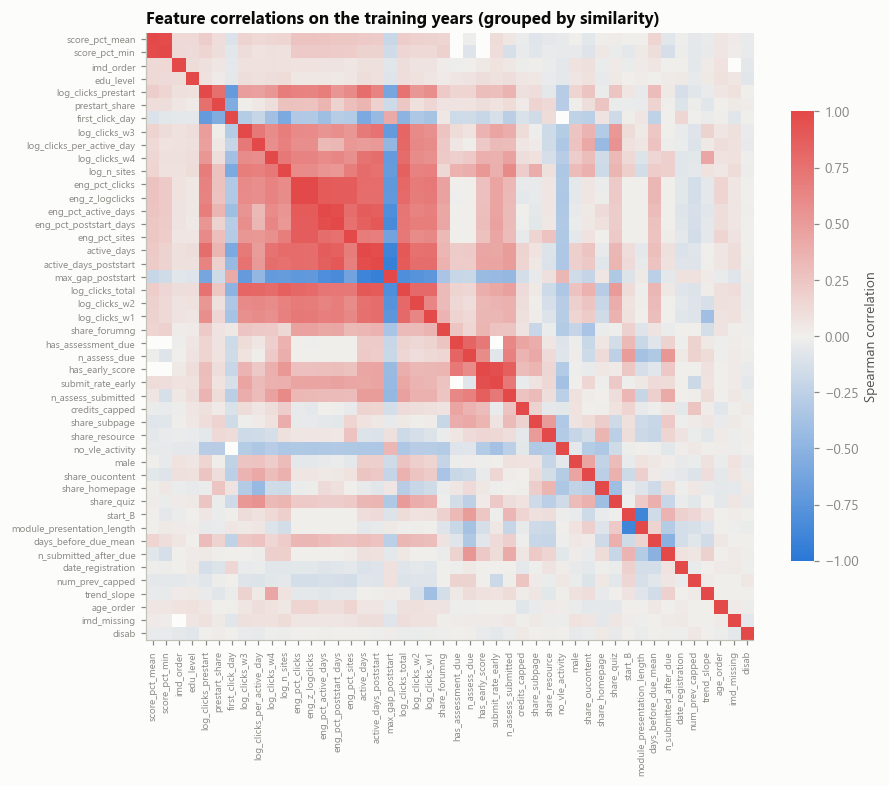

In [9]:
rho = train[NUM_ALL].corr(method="spearman")
dist = 1 - rho.abs().fillna(0).to_numpy()
np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), method="average")
cl = pd.Series(fcluster(Z, t=0.10, criterion="distance"), index=NUM_ALL)
uni_auc = pd.Series({c: abs(2 * (1 - auc_pos(train[c], train.target_at_risk)) - 1) for c in NUM_ALL})   # separation 0..1
groups_ = cl.groupby(cl).apply(lambda s: list(s.index))
multi = groups_[groups_.map(len) > 1]
print(f"{len(NUM_ALL)} numeric features fall into {cl.nunique()} groups at |rho| >= 0.9; {len(multi)} groups have more than one member:")
KEEP, DROP = [], {}
for gid, members in groups_.items():
    best = max(members, key=lambda m: uni_auc[m])
    KEEP.append(best)
    for m in members:
        if m != best: DROP[m] = best
for gid, members in multi.items():
    best = max(members, key=lambda m: uni_auc[m])
    print(f"  keep {best:28s} drop {[m for m in members if m != best]}")

ordered = rho.loc[sorted(NUM_ALL, key=lambda c: (cl[c], c)), sorted(NUM_ALL, key=lambda c: (cl[c], c))]
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(8.4, 7.2))
im = ax.imshow(ordered, cmap=cmap, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(ordered)), ordered.columns, rotation=90, fontsize=6.5); ax.set_yticks(range(len(ordered)), ordered.index, fontsize=6.5)
cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.set_label("Spearman correlation"); cb.outline.set_visible(False)
ax.set_title("Feature correlations on the training years (grouped by similarity)")
fig.tight_layout(); savefig(fig, "04_correlation_groups.png"); plt.show()

**Observed.** Only 5 of 40 groups contain more than one feature at |Spearman| of 0.9 or more. Six features are dropped as near-duplicates of a better-separating partner: `score_pct_min`, `eng_z_logclicks`, `eng_pct_active_days`, `active_days`, `max_gap_poststart`, and `has_early_score`.
The heatmap shows large blocks of moderate correlation (0.5 to 0.9) among the engagement variables, which the 0.9 rule leaves in place; they are handled by the VIF check at the end.
**Action.** Use the 42 remaining candidates (40 numeric, 2 categorical) in the rankings.

### 5.2 Model helpers (fitted steps stay inside pipelines)

In [10]:
cv = GroupKFold(n_splits=5)

def make_pre(num_cols, cat_cols, scaled):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]) if scaled else "passthrough"
    parts = []
    if num_cols: parts.append(("num", num, num_cols))
    if cat_cols: parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols))
    return ColumnTransformer(parts)

def make_pipe(num_cols, cat_cols, kind):
    if kind == "logit":
        est = LogisticRegression(max_iter=3000, C=1.0)
    else:
        est = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, random_state=RANDOM_STATE)
    return Pipeline([("pre", make_pre(num_cols, cat_cols, scaled=(kind == "logit"))), ("m", est)])

def cv_auc(num_cols, cat_cols, kind, data=None):
    data = train if data is None else data
    cols = list(num_cols) + list(cat_cols)
    s = cross_val_score(make_pipe(num_cols, cat_cols, kind), data[cols], data.target_at_risk, groups=data.id_student, cv=cv, scoring="roc_auc")
    return s.mean(), s.std()

base = cv_auc(["start_B", "module_presentation_length"], ["code_module"], "hgb")
print("sanity check, module and season only (HGB, grouped 5-fold CV on 2013): AUC %.3f +/- %.3f" % base)

sanity check, module and season only (HGB, grouped 5-fold CV on 2013): AUC 0.570 +/- 0.014


### 5.3 Which feature families add predictive value? (ablation, training years only)

In [11]:
def num(*gs): return [c for g in gs for c in GROUPS[g]["num"]]
def cat(*gs): return [c for g in gs for c in GROUPS[g]["cat"]]
sets = {
    "1 context only": (num("context"), cat("context")),
    "2 background only": (num("background"), cat("background")),
    "3 context + raw engagement": (num("context", "engagement_raw"), cat("context")),
    "4 context + raw engagement + OLD score features": (num("context", "engagement_raw") + ASSESS_OLD, cat("context")),
    "5 context + raw engagement + NEW assessment features": (num("context", "engagement_raw", "assessment"), cat("context")),
    "6 context + raw + relative engagement + assessment": (num("context", "engagement_raw", "engagement_relative", "assessment"), cat("context")),
    "7 everything (adds background)": (NUM_ALL, CAT_ALL),
}
rows = []
for name, (nc, cc) in sets.items():
    l, hg = cv_auc(nc, cc, "logit"), cv_auc(nc, cc, "hgb")
    rows.append(dict(feature_set=name, n_features=len(nc) + len(cc), logit_auc=l[0], logit_sd=l[1], hgb_auc=hg[0], hgb_sd=hg[1]))
ablation = pd.DataFrame(rows).set_index("feature_set")
ablation.to_csv(OUT / "ablation_cv_auc.csv")
ablation

,n_features,logit_auc,logit_sd,hgb_auc,hgb_sd
feature_set,,,,,
1 context only,4,0.572,0.013,0.570,0.014
2 background only,10,0.649,0.012,0.652,0.012
3 context + raw engagement,25,0.725,0.011,0.725,0.011
4 context + raw engagement + OLD score features,30,0.773,0.010,0.774,0.011
5 context + raw engagement + NEW assessment features,33,0.771,0.008,0.780,0.010
6 context + raw + relative engagement + assessment,38,0.772,0.009,0.779,0.010
7 everything (adds background),48,0.787,0.010,0.793,0.010


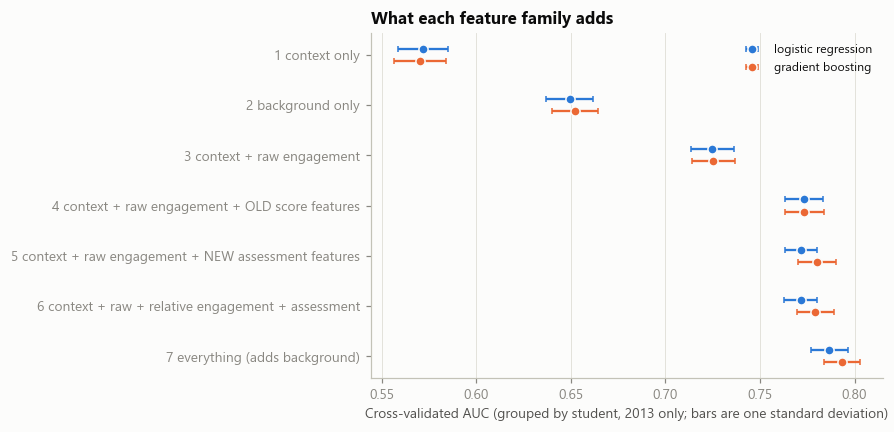

In [12]:
fig, ax = plt.subplots(figsize=(8.2, 4))
y = np.arange(len(ablation))[::-1]
ax.errorbar(ablation.logit_auc, y + 0.12, xerr=ablation.logit_sd, fmt="o", color=C_OK, ecolor=C_OK, capsize=2, markersize=6, markeredgecolor=SURFACE, label="logistic regression")
ax.errorbar(ablation.hgb_auc, y - 0.12, xerr=ablation.hgb_sd, fmt="o", color=C_RISK, ecolor=C_RISK, capsize=2, markersize=6, markeredgecolor=SURFACE, label="gradient boosting")
ax.set_yticks(y, ablation.index); ax.set_xlabel("Cross-validated AUC (grouped by student, 2013 only; bars are one standard deviation)")
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.set_title("What each feature family adds")
fig.tight_layout(); savefig(fig, "04_ablation.png"); plt.show()

**Observed (cross-validated AUC, 2013 only, grouped by student).** Module and season alone give 0.57, barely above chance. Background alone gives 0.65. Raw engagement lifts the model to 0.725. The new early-assessment features add about 0.05 (to 0.771 for logistic regression and 0.780 for gradient boosting). Relative engagement adds nothing on top when the module is already a feature (0.772 and 0.779). Background adds a further 0.01 to 0.015 (0.787 and 0.793 with everything).
Old and new score features perform the same here (0.773 and 0.774 vs 0.771 and 0.780), as expected, since the artefact does not occur in 2013. The two model types agree within about one standard deviation (0.010), so most of the signal is additive and a simple logistic model is nearly as good as boosting.

**Why it matters.** Combinations of features reach about 0.79, far above the best single feature (0.67), and early assessment behaviour is the largest single family. The relative engagement features are redundant *given the module*, which is what the next test is for.
**Caution.** All of this is within 2013. The 2014 test set has not been touched.

### 5.3b Predicting a module the model has never seen

Module CCC (22% of the 2014 test rows) never appears in the 2013 training years. The ablation above always included the module as a feature, which hides the value of engagement measured *relative to the module*.
Here each module is held out in turn, and the model is trained on the remaining ones with **no module information at all** (no module dummy, no season, no course length).

In [13]:
from sklearn.model_selection import LeaveOneGroupOut
y_tr = train.target_at_risk
def lomo(num_cols, kind):
    res = {}
    for tr, va in LeaveOneGroupOut().split(train, groups=train.code_module):
        mod = train.code_module.iloc[va].iloc[0]
        pipe = make_pipe(num_cols, [], kind).fit(train.iloc[tr][num_cols], y_tr.iloc[tr])
        res[mod] = roc_auc_score(y_tr.iloc[va], pipe.predict_proba(train.iloc[va][num_cols])[:, 1])
    return res

lomo_sets = {
    "raw engagement + assessment": GROUPS["engagement_raw"]["num"] + GROUPS["assessment"]["num"],
    "relative engagement + assessment": GROUPS["engagement_relative"]["num"] + GROUPS["assessment"]["num"],
    "raw + relative engagement + assessment": GROUPS["engagement_raw"]["num"] + GROUPS["engagement_relative"]["num"] + GROUPS["assessment"]["num"],
}
rows = []
for name, cols in lomo_sets.items():
    for kind in ("logit", "hgb"):
        r = lomo(cols, kind); rows.append(dict(feature_set=name, model=kind, **{k: v for k, v in r.items()}, mean_auc=np.mean(list(r.values()))))
lomo_df = pd.DataFrame(rows).set_index(["feature_set", "model"])
lomo_df.to_csv(OUT / "leave_one_module_out_auc.csv")
lomo_df

AAA   BBB   DDD   EEE   FFF   GGG  mean_auc
feature_set                            model                                              
raw engagement + assessment            logit 0.744 0.759 0.729 0.726 0.730 0.587     0.713
                                       hgb   0.748 0.766 0.802 0.729 0.736 0.587     0.728
relative engagement + assessment       logit 0.742 0.756 0.747 0.756 0.734 0.608     0.724
                                       hgb   0.755 0.764 0.812 0.748 0.740 0.608     0.738
raw + relative engagement + assessment logit 0.734 0.759 0.745 0.749 0.736 0.603     0.721
                                       hgb   0.753 0.766 0.808 0.738 0.745 0.606     0.736

**Observed.** With no module information, relative engagement predicts unseen modules better than raw engagement: mean AUC 0.738 vs 0.728 for gradient boosting and 0.724 vs 0.713 for logistic regression. The gain is clearest for EEE (+0.019 and +0.030), GGG (+0.021 and +0.021) and DDD (+0.010 and +0.018), and absent for BBB. Adding the raw features on top of the relative ones gives nothing more.
Prediction for a module the model has not seen (mean AUC 0.71 to 0.74) is clearly worse than prediction within known modules (0.78 to 0.79), and GGG is the hardest module (about 0.6).

**Why it matters.** This justifies the relative features: they are redundant when the module is known and useful when it is not, and 22% of the test rows come from a module never seen in training.
**Action.** Keep relative features in the candidate pool, and expect a lower test AUC for module CCC.

### 5.4 Rank the features three ways (mutual information, L1 stability, permutation importance)

Only the features that survived the redundancy filter enter the ranking.

In [14]:
cand_num = [c for c in NUM_ALL if c in KEEP]
cand_cat = CAT_ALL[:]
cand = cand_num + cand_cat
print(f"{len(cand_num)} numeric + {len(cand_cat)} categorical candidates after the redundancy filter (removed: {sorted(DROP)})")

# (a) mutual information with the target
Xmi = pd.concat([pd.DataFrame(SimpleImputer(strategy="median").fit_transform(train[cand_num]), columns=cand_num),
                 pd.DataFrame(OrdinalEncoder().fit_transform(train[cand_cat]), columns=cand_cat)], axis=1)
is_disc = np.array([train[c].nunique() <= 12 for c in cand_num] + [True] * len(cand_cat))
for c, disc in zip(cand_num, is_disc[:len(cand_num)]):   # discrete mode wants integer codes, not floats
    if disc: Xmi[c] = pd.factorize(Xmi[c])[0]
mi = pd.Series(mutual_info_classif(Xmi, train.target_at_risk, discrete_features=is_disc, random_state=RANDOM_STATE), index=cand)

# (b) L1 stability: how often is a feature kept by an L1 logistic model across 30 student-grouped subsamples?
L1_C = 0.01   # strong penalty so that only the clearest features survive each subsample
pre_l1 = make_pre(cand_num, cand_cat, scaled=True)
gss = GroupShuffleSplit(n_splits=30, train_size=0.7, random_state=RANDOM_STATE)
hits = pd.Series(0.0, index=cand)
for tr, _ in gss.split(train, groups=train.id_student):
    sub = train.iloc[tr]
    Xs = pre_l1.fit_transform(sub[cand])
    m = LogisticRegression(l1_ratio=1.0, solver="saga", C=L1_C, max_iter=5000).fit(Xs, sub.target_at_risk)
    names = pre_l1.get_feature_names_out()
    nz = {n for n, w in zip(names, m.coef_[0]) if abs(w) > 1e-8}
    for c in cand_num: hits[c] += (f"num__{c}" in nz)
    for c in cand_cat: hits[c] += any(n.startswith(f"cat__{c}_") for n in nz)
l1_freq = hits / gss.n_splits

# (c) permutation importance of a gradient-boosting model, measured on held-out folds
perm = pd.DataFrame(index=cand, dtype=float)
for k, (tr, va) in enumerate(cv.split(train, groups=train.id_student)):
    pipe = make_pipe(cand_num, cand_cat, "hgb").fit(train.iloc[tr][cand], train.iloc[tr].target_at_risk)
    r = permutation_importance(pipe, train.iloc[va][cand], train.iloc[va].target_at_risk, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
    perm[f"fold{k}"] = r.importances_mean
perm_mean = perm.mean(axis=1)

rank = pd.DataFrame({"mutual_info": mi, "l1_selection_freq": l1_freq, "perm_importance_auc": perm_mean})
rank["rank_mi"] = rank.mutual_info.rank(ascending=False); rank["rank_l1"] = rank.l1_selection_freq.rank(ascending=False, method="average")
rank["rank_perm"] = rank.perm_importance_auc.rank(ascending=False)
rank["mean_rank"] = rank[["rank_mi", "rank_l1", "rank_perm"]].mean(axis=1)
rank["group"] = [next(g for g, v in GROUPS.items() if c in v["num"] + v["cat"]) for c in rank.index]
rank = rank.sort_values("mean_rank")
rank.head(25)

40 numeric + 2 categorical candidates after the redundancy filter (removed: ['active_days', 'eng_pct_active_days', 'eng_z_logclicks', 'has_early_score', 'max_gap_poststart', 'score_pct_min'])


,mutual_info,l1_selection_freq,perm_importance_auc,rank_mi,rank_l1,rank_perm,mean_rank,group
eng_pct_poststart_days,0.079,1.000,0.019,1.000,6.000,3.000,3.333,engagement_relative
score_pct_mean,0.060,1.000,0.056,4.000,6.000,1.000,3.667,assessment
submit_rate_early,0.057,1.000,0.028,5.000,6.000,2.000,4.333,assessment
eng_pct_sites,0.072,1.000,0.002,3.000,6.000,8.000,5.667,engagement_relative
days_before_due_mean,0.025,1.000,0.016,17.000,6.000,5.000,9.333,assessment
share_subpage,0.033,0.967,0.001,10.000,12.500,10.000,10.833,engagement_raw
eng_pct_clicks,0.075,0.100,0.001,2.000,21.000,11.000,11.333,engagement_relative
edu_level,0.014,1.000,0.018,26.000,6.000,4.000,12.000,background
credits_capped,0.016,1.000,0.002,23.000,6.000,9.000,12.667,background
imd_order,0.011,1.000,0.006,27.000,6.000,6.000,13.000,background


**Observed.** The three criteria agree on the top group: `eng_pct_poststart_days`, `score_pct_mean`, `submit_rate_early`, `eng_pct_sites` and `days_before_due_mean`. Permutation importance is dominated by assessment behaviour (dropping `score_pct_mean` costs 0.056 AUC and `submit_rate_early` 0.028), followed by `eng_pct_poststart_days` (0.019), `edu_level` (0.018) and `days_before_due_mean` (0.016).
Several raw engagement features have high mutual information but zero L1 frequency and zero permutation importance: they carry the same information as a relative feature that ranks higher, so a model gains nothing from them.
**Why it matters.** Past about the first ten features, the permutation importances are close to zero and the order is within noise; only the top ten should be read as meaningful.

### 5.5 How many features? (performance against the number kept)

best mean AUC 0.7897; smallest k within 0.005 of the best: k = 20


,logit_auc,hgb_auc,mean_auc
k,,,
3,0.757,0.759,0.758
5,0.759,0.771,0.765
8,0.770,0.783,0.777
10,0.776,0.787,0.782
12,0.777,0.788,0.783
15,0.778,0.789,0.784
20,0.784,0.793,0.788
25,0.785,0.793,0.789
42,0.787,0.793,0.790


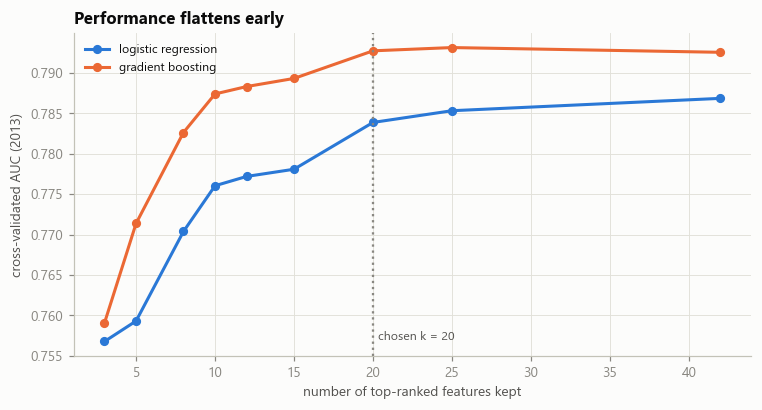

In [15]:
order = list(rank.index)
ks = [3, 5, 8, 10, 12, 15, 20, 25, len(order)]
ks = sorted(set(k for k in ks if k <= len(order)))
rows = []
for k in ks:
    top = order[:k]
    nc, cc = [c for c in top if c in cand_num], [c for c in top if c in cand_cat]
    l, hg = cv_auc(nc, cc, "logit"), cv_auc(nc, cc, "hgb")
    rows.append(dict(k=k, logit_auc=l[0], hgb_auc=hg[0]))
kcurve = pd.DataFrame(rows).set_index("k")
kcurve["mean_auc"] = kcurve[["logit_auc", "hgb_auc"]].mean(axis=1)
TOL = 0.005   # the cross-validation standard deviation is about 0.010, so differences under 0.005 are within noise
k_star = int(kcurve[kcurve.mean_auc >= kcurve.mean_auc.max() - TOL].index.min())
print(f"best mean AUC {kcurve.mean_auc.max():.4f}; smallest k within {TOL} of the best: k = {k_star}")
display(kcurve)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(kcurve.index, kcurve.logit_auc, "-o", color=C_OK, linewidth=2, markersize=5, label="logistic regression")
ax.plot(kcurve.index, kcurve.hgb_auc, "-o", color=C_RISK, linewidth=2, markersize=5, label="gradient boosting")
ax.axvline(k_star, color=MUTED, linestyle=":"); ax.text(k_star + 0.3, ax.get_ylim()[0] + 0.002, f"chosen k = {k_star}", color=INK2, fontsize=8)
ax.set_xlabel("number of top-ranked features kept"); ax.set_ylabel("cross-validated AUC (2013)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Performance flattens early")
fig.tight_layout(); savefig(fig, "04_k_curve.png"); plt.show()

**Observed.** Three features already reach a mean AUC of 0.758; ten reach 0.782; the full set of 42 reaches 0.790. The smallest set within the 0.005 tolerance of the best is 20 features (0.788).
**Action.** Keep the top 20, then prune multicollinearity (next).

### 5.6 Final selected set, multicollinearity and saving

In [16]:
top_k = order[:k_star]
num_k = [c for c in top_k if c in cand_num]
print(f"TOP {k_star} BY RANK (before the multicollinearity check):")
display(rank.loc[top_k, ["group", "mutual_info", "l1_selection_freq", "perm_importance_auc", "mean_rank"]])

def vif_table(feats):
    X = pd.DataFrame(StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(train[feats])), columns=feats)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=feats)

# Multicollinearity pruning: while any VIF exceeds 10, drop the least important (highest mean rank) feature among those above 10.
VIF_MAX = 10.0
feats, removed_log = num_k[:], []
while len(feats) > 3:
    v = vif_table(feats)
    over = v[v > VIF_MAX]
    if over.empty: break
    drop = max(over.index, key=lambda c: rank.loc[c, "mean_rank"])
    removed_log.append(dict(removed=drop, vif_at_removal=v[drop], mean_rank=rank.loc[drop, "mean_rank"])); feats.remove(drop)
print("\nFeatures removed for VIF above", VIF_MAX, ":")
display(pd.DataFrame(removed_log) if removed_log else "none")

sel_num = feats
sel_cat = [c for c in top_k if c in cand_cat]
selected = sel_num + sel_cat
rank["selected"] = rank.index.isin(selected)
vif = vif_table(sel_num).sort_values(ascending=False)
print(f"\nFINAL SELECTED SET: {len(selected)} features; by family:", rank.loc[selected].group.value_counts().to_dict())
print("Largest remaining variance inflation factors:")
display(vif.round(2).to_frame("VIF").head(6))

TOP 20 BY RANK (before the multicollinearity check):


,group,mutual_info,l1_selection_freq,perm_importance_auc,mean_rank
eng_pct_poststart_days,engagement_relative,0.079,1.000,0.019,3.333
score_pct_mean,assessment,0.060,1.000,0.056,3.667
submit_rate_early,assessment,0.057,1.000,0.028,4.333
eng_pct_sites,engagement_relative,0.072,1.000,0.002,5.667
days_before_due_mean,assessment,0.025,1.000,0.016,9.333
share_subpage,engagement_raw,0.033,0.967,0.001,10.833
eng_pct_clicks,engagement_relative,0.075,0.100,0.001,11.333
edu_level,background,0.014,1.000,0.018,12.000
credits_capped,background,0.016,1.000,0.002,12.667
imd_order,background,0.011,1.000,0.006,13.000



Features removed for VIF above 10.0 :


,removed,vif_at_removal,mean_rank
0,log_n_sites,20.029,21.000
1,active_days_poststart,12.356,19.000



FINAL SELECTED SET: 18 features; by family: {'engagement_raw': 5, 'background': 4, 'assessment': 4, 'engagement_relative': 3, 'context': 2}
Largest remaining variance inflation factors:


,VIF
eng_pct_clicks,9.280
log_clicks_total,6.440
log_clicks_w1,5.680
eng_pct_poststart_days,5.430
eng_pct_sites,4.710
log_clicks_w2,3.040


In [17]:
final_l = cv_auc(sel_num, sel_cat, "logit"); final_h = cv_auc(sel_num, sel_cat, "hgb")
full_l = ablation.loc["7 everything (adds background)"]
print(f"selected set ({len(selected)} features): logit AUC {final_l[0]:.4f} (sd {final_l[1]:.3f}), HGB AUC {final_h[0]:.4f} (sd {final_h[1]:.3f})")
print(f"all {len(NUM_ALL) + len(CAT_ALL)} features:           logit AUC {full_l.logit_auc:.4f}, HGB AUC {full_l.hgb_auc:.4f}")

feature_table = F[KEY + ["year", "split", "target_final_result", "target_at_risk"] + NUM_ALL + DROPPED_CONST + CAT_ALL + ASSESS_OLD].copy()
feature_table = feature_table.loc[:, ~feature_table.columns.duplicated()]
feature_table.to_csv(PROC / "oulad_features_day28.csv", index=False)
rank.to_csv(OUT / "feature_selection_summary.csv")
spec = {"cutoff_day": CUTOFF_DAY, "split": "train = year 2013, test = year 2014", "numeric_candidates": NUM_ALL, "categorical_candidates": CAT_ALL,
        "removed_no_variation_in_train": DROPPED_CONST, "removed_as_redundant": DROP, "selected_numeric": sel_num, "selected_categorical": sel_cat, "k_before_vif": k_star, "removed_for_vif": [r["removed"] for r in removed_log],
        "groups": {k: v["num"] + v["cat"] for k, v in GROUPS.items()}}
(OUT / "feature_groups.json").write_text(json.dumps(spec, indent=2))
print("saved", PROC / "oulad_features_day28.csv", feature_table.shape)

selected set (18 features): logit AUC 0.7838 (sd 0.009), HGB AUC 0.7926 (sd 0.009)
all 48 features:           logit AUC 0.7867, HGB AUC 0.7934


saved ..\data\processed\oulad_features_day28.csv (27553, 58)


**Observed.** The VIF check removed `log_n_sites` (VIF 20.0) and `active_days_poststart` (12.4), leaving 18 features with a maximum VIF of 9.3 (`eng_pct_clicks`; all others 6.5 or less). The final set has 18 features and matches the full 48 in cross-validated AUC (logistic 0.784 vs 0.787, boosting 0.793 vs 0.793).

**Final selected features**

| Family | Features |
|---|---|
| Assessment (4) | `score_pct_mean`, `submit_rate_early`, `days_before_due_mean`, `n_submitted_after_due` |
| Relative engagement (3) | `eng_pct_poststart_days`, `eng_pct_sites`, `eng_pct_clicks` |
| Raw engagement (5) | `share_subpage`, `log_clicks_w1`, `log_clicks_w2`, `log_clicks_total`, `trend_slope` |
| Background (4) | `edu_level`, `credits_capped`, `imd_order`, `num_prev_capped` |
| Context (2) | `code_module`, `module_presentation_length` |

The last four or five features in rank order are marginal; dropping them would change the AUC by less than the cross-validation noise.

## 6. Synthesis

**What changed in the data.** Early assessment scores are now percentile ranks inside each assessment, which removes a coding artefact that would have appeared only in the 2014 test set. Engagement is available both raw and relative to the module-presentation. Counts are log-transformed, extreme credit values are capped, and near-constant flags and binary-completion features are excluded.

**What drives risk at day 28 (training years only).**

1. Early assessment behaviour is the strongest family: whether and how early students submit, and how their score ranks among peers.
2. Engagement relative to the module adds information that generalises to modules the model has not seen.
3. Background (prior education, deprivation, previous attempts, credits) adds a smaller but real share (about 0.01 to 0.015 AUC) beyond behaviour.
4. Module and season alone say very little (AUC 0.57).

**Limits to carry forward.**

- All numbers here are cross-validated on 2013 only; the real test is 2014.
- Module CCC (22% of the test rows) is unseen; expect a lower AUC there (about 0.71 to 0.74 in the leave-one-module-out check).
- Feature selection used the same training rows as the cross-validation, so the selected-set scores are slightly optimistic. The 2014 test is the unbiased estimate.
- 9.3% of the test rows are returning students.

**Decisions for the next notebooks**

| Notebook | Use |
|---|---|
| 05 clustering | Cluster on log-scaled and relative engagement features (not on the labels), compare k-means, hierarchical, DBSCAN and GMM; profile clusters against risk |
| 06 association rules and categorical analysis | Discretise engagement tertiles and assessment behaviour; merge only rare education and age levels, and document it |
| 07 modelling and drift | Fit the selected set on 2013, test on 2014; report per module (CCC separately), with and without returning students, and compare old and new score features on 2014 to show the artefact's effect; fairness by IMD, disability, age and education |